# Practical 9: DBSCAN (Density-Based Clustering)

**Aim:** Use DBSCAN to find the cluster structure and the noise points in a dataset.

**Dataset:** `make_moons` (two half-moon shapes) plus a few random outliers. This shows what DBSCAN does well and what K-Means cannot do.

**Key terms**
- **eps**: the radius of the neighbourhood around a point.
- **min_samples**: how many points must be inside eps for the area to count as dense.
- **Noise points** get the label **-1** (they belong to no cluster).

**Steps:** 1) Make and scale the data  2) Choose eps (k-distance plot)  3) Run DBSCAN  4) Compare with K-Means  5) Effect of eps

## Step 1: Make the data

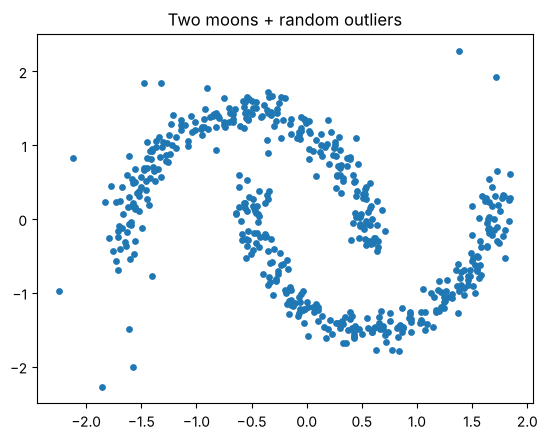

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score

X, true_labels = make_moons(n_samples=500, noise=0.07, random_state=42)

# Add 15 random outliers so there are real noise points to find
np.random.seed(1)
outliers = np.random.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(15, 2))
X = np.vstack([X, outliers])

X = StandardScaler().fit_transform(X)    # DBSCAN uses distances, so scale

plt.scatter(X[:, 0], X[:, 1], s=15)
plt.title("Two moons + random outliers")
plt.show()

## Step 2: Choose eps with the k-distance plot
For every point we find the distance to its 5th nearest neighbour, sort these distances and plot them. Points in dense areas have small distances; outliers have large ones. The **knee** (where the curve bends up sharply) is a good eps.

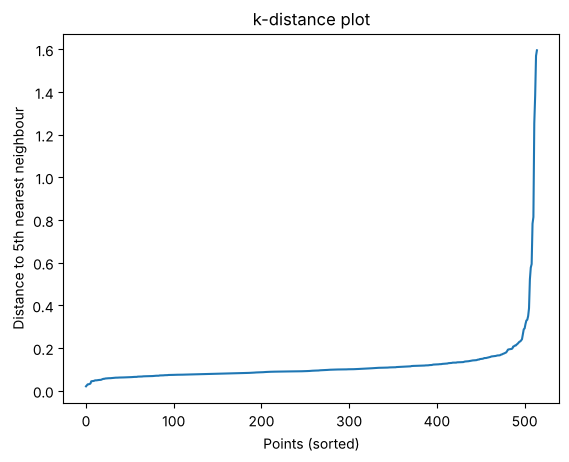

In [2]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X)
distances, _ = neighbors.kneighbors(X)

k_distances = np.sort(distances[:, -1])    # distance to the 5th neighbour, sorted

plt.plot(k_distances)
plt.xlabel("Points (sorted)")
plt.ylabel("Distance to 5th nearest neighbour")
plt.title("k-distance plot")
plt.show()

**How to read:** the curve is flat for most points (dense areas) and then shoots up at the right end (sparse points and outliers). The knee is at a distance of about **0.2 to 0.3**, so we use eps = 0.25.

## Step 3: Run DBSCAN

Clusters found: 2
Noise points  : 10


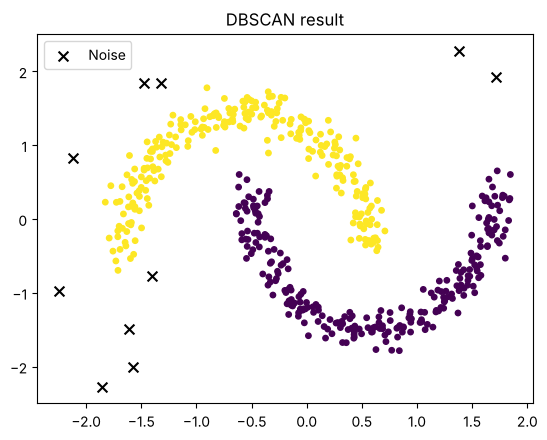

In [3]:
db = DBSCAN(eps=0.25, min_samples=5)
labels = db.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print("Clusters found:", n_clusters)
print("Noise points  :", n_noise)

# Plot: noise = black crosses
plt.scatter(X[labels != -1, 0], X[labels != -1, 1], c=labels[labels != -1], s=15)
plt.scatter(X[labels == -1, 0], X[labels == -1, 1], c="black", marker="x", s=50, label="Noise")
plt.title("DBSCAN result")
plt.legend()
plt.show()

**How to read:** each colour is a cluster and the **black crosses are noise** (label -1): points in low-density areas that belong to no cluster. DBSCAN found the **2 moons** without being told the number of clusters. We added 15 outliers but only about 10 were marked as noise: the others landed close to a moon, so they were counted as part of it.

## Step 4: DBSCAN vs K-Means

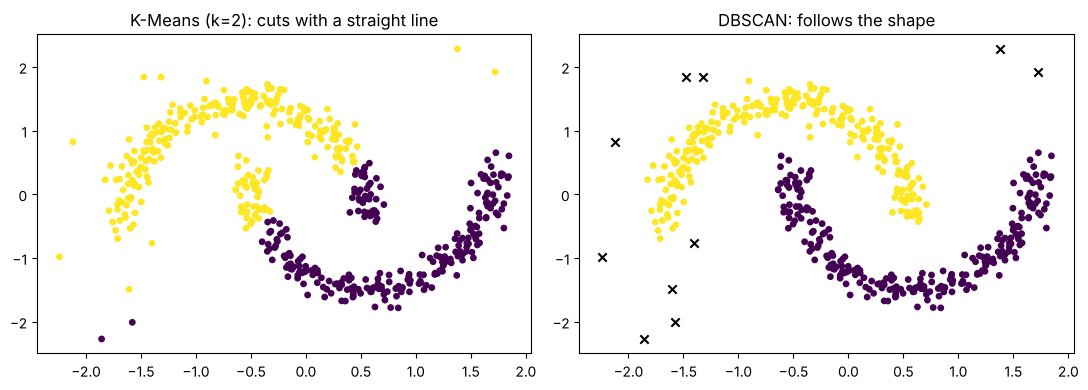

K-Means score: 0.445
DBSCAN score : 1.0


In [4]:
kmeans_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, s=15)
plt.title("K-Means (k=2): cuts with a straight line")

plt.subplot(1, 2, 2)
plt.scatter(X[labels != -1, 0], X[labels != -1, 1], c=labels[labels != -1], s=15)
plt.scatter(X[labels == -1, 0], X[labels == -1, 1], c="black", marker="x")
plt.title("DBSCAN: follows the shape")

plt.tight_layout()
plt.show()

# How close is each result to the true moons? (1 = perfect) - only the first 500 real points
print("K-Means score:", round(adjusted_rand_score(true_labels, kmeans_labels[:500]), 3))
mask = labels[:500] != -1
print("DBSCAN score :", round(adjusted_rand_score(true_labels[mask], labels[:500][mask]), 3))

**How to read:** K-Means assumes round clusters around a centre, so it splits the plane with a straight line and mixes the two moons. DBSCAN grows clusters through connected dense areas, so it follows the curved shape. The scores (1 = perfect) confirm it.

## Step 5: What happens if eps is too small or too big?

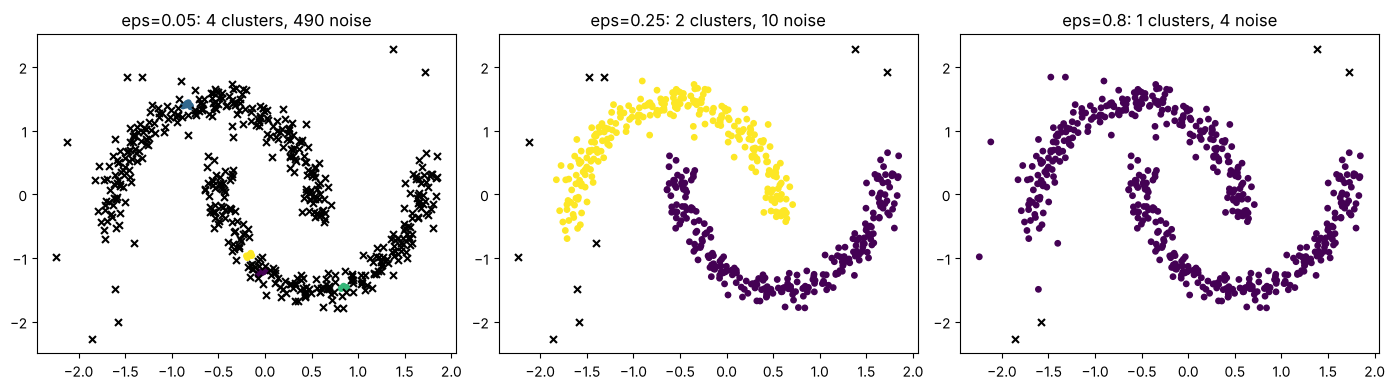

In [5]:
plt.figure(figsize=(14, 4))
for i, eps in enumerate([0.05, 0.25, 0.8]):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    n_c = len(set(lab)) - (1 if -1 in lab else 0)
    n_n = list(lab).count(-1)
    plt.subplot(1, 3, i + 1)
    plt.scatter(X[lab != -1, 0], X[lab != -1, 1], c=lab[lab != -1], s=15)
    plt.scatter(X[lab == -1, 0], X[lab == -1, 1], c="black", marker="x", s=25)
    plt.title("eps=" + str(eps) + ": " + str(n_c) + " clusters, " + str(n_n) + " noise")
plt.tight_layout()
plt.show()

**How to read:**
- **eps too small (0.05):** almost no area is dense enough, so most points become noise.
- **eps just right (0.25):** two clusters (the moons) and a few noise points.
- **eps too large (0.8):** the two moons merge into one cluster and the noise disappears.

## Conclusion
DBSCAN found the two moon-shaped clusters and marked outliers as noise without being told the number of clusters, and it did much better than K-Means on non-round shapes. The result depends strongly on eps: the k-distance plot helps choose it.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is DBSCAN?**
Density-Based Spatial Clustering of Applications with Noise. It groups points that are closely packed (high density) and marks points in low-density regions as noise.

**Q2. What are its two parameters?**
`eps`, the neighbourhood radius, and `min_samples`, the minimum number of points to form a dense region.

**Q3. Explain core, border and noise points.**
Core: at least `min_samples` points within eps. Border: within eps of a core point but not core itself. Noise: neither.

**Q4. Explain the algorithm.**
Pick an unvisited point. If it is a core point, start a new cluster and add all density-reachable points, expanding through other core points. If it is not core, mark it as noise (it may later turn out to be a border point). Repeat until all points are visited.

**Q5. What is density-reachable and density-connected?**
A point q is density-reachable from p if there is a chain of core points from p to q, each within eps of the next. Two points are density-connected if both are reachable from a common core point.

**Q6. DBSCAN vs K-Means?**
DBSCAN needs no number of clusters, finds arbitrary shapes, detects noise, but is sensitive to eps and struggles with varying densities. K-Means needs k, finds only spherical clusters, assigns every point to a cluster (no noise concept) and is faster on large data.

**Q7. How do you choose eps and min_samples?**
`min_samples` is about 2 × the number of dimensions (at least 3 to 5). eps comes from the knee of the k-distance plot.

**Q8. Is DBSCAN sensitive to scaling?**
Yes, it is distance-based, so scale the features first.

**Q9. What are the drawbacks of DBSCAN?**
Hard to choose eps; fails when clusters have very different densities (one eps cannot fit all); poor in high dimensions (distances lose meaning); border points can be assigned differently depending on the processing order.

**Q10. What does label -1 mean?**
Noise (an outlier).

**Q11. Can DBSCAN be used for anomaly detection?**
Yes, the noise points are candidate anomalies.

**Q12. What distance metric does it use?**
Euclidean by default; others (Manhattan, cosine) can be set with `metric=`.

**Q13. Time complexity?**
$O(n\log n)$ with a spatial index such as a KD-tree, $O(n^2)$ without.

**Q14. What is HDBSCAN?**
An extension that removes the need for eps and handles clusters of varying density.

**Q15. How do you evaluate DBSCAN?**
Silhouette score on non-noise points, Davies-Bouldin index, or Adjusted Rand Index if true labels exist; also report the noise percentage.

**Q16. Does DBSCAN need the number of clusters in advance?**
No. The number of clusters is a result.

**Q17. Is DBSCAN deterministic?**
Core points and noise are deterministic; border points reachable from two clusters may be assigned to either, depending on order.

**Q18. What happens if eps is too small? Too large?**
Too small: most points become noise and many tiny clusters appear. Too large: clusters merge into one.

**Q19. What happens if `min_samples` is increased?**
A denser region is required, so more points become noise and small clusters disappear; the result is more conservative.

**Q21. Can DBSCAN find clusters of different shapes?**
Yes, any shape (even non-convex ones like moons, rings and spirals).

## B. Questions about the graphs

**G1. How do you read the k-distance plot?**
Each point's distance to its k-th nearest neighbour is sorted ascending. The curve is flat for dense-region points and rises sharply for sparse points and outliers. The y-value at the knee is the best eps.

**G2. What do the black crosses mean in the cluster plot?**
Noise points (label -1): points in low-density regions that belong to no cluster.

**G3. Why does DBSCAN beat K-Means on the moons?**
DBSCAN follows dense regions and forms arbitrarily shaped clusters; K-Means assumes round clusters around centroids, so it splits the moons with a straight boundary.

**G4. How many clusters did DBSCAN find and how do you know?**
Count the unique labels excluding -1. The number of clusters comes from the data, not from the user.

**G5. What does the eps sensitivity grid show?**
Tiny eps gives mostly noise and many clusters; the right eps gives the true structure; a large eps merges everything into one cluster with no noise.

## C. Code questions

**C1. What does `db.labels_` contain?**
The cluster index of each point; -1 means noise.

**C3. Why add random outliers in Part A?**
To have genuine noise points to detect, which demonstrates DBSCAN's outlier handling.

**C4. Why `NearestNeighbors(n_neighbors=min_samples)`?**
To get each point's distance to its min_samples-th neighbour for the k-distance plot.